# <font color=DodgerBlue>Rahnema College ML Bootcamp Challenge</font>
*M. Mahdi Mostafaei*

______________

##  <font color=DodgerBlue >Task B:</font>  Gradient Descent Regression

Importing needed libaries:

In [15]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing

import matplotlib.pyplot as plt

Loading & splitting wine dataset as challenge insrtuctions:

First trying with one feature: `median income`

In [16]:
# Load dataset
data = fetch_california_housing()
X, y = data.data, data.target

# Start with ONE feature: median income (Column 0)
X_single = X[:, [0]] 

# Split the single-feature data
X_train_single, X_test_single, y_train, y_test = train_test_split(
    X_single, y, test_size=0.2, random_state=42
)

### Algorithm

Creating a class for GD Regressor with linear hypothesis  $h_{\theta}(x) = \theta_0 + \theta_1x$ 

And MSE loss function  $\mathcal{L}(\theta) = \Bigl(h_{\theta}(x^{(i)}) - y^{(i)} \Bigl)^2$

Which computes the total cost  $J(\theta) = \frac{1}{2m} \sum_{i=1}^m \left( h_\theta(x^{(i)}) - y^{(i)} \right)^2$

Then updates the $\theta_0$ and $\theta_1$ by derivating the cost:  $\theta_j := \theta_j - \alpha \frac{1}{m} \sum_{i=1}^m \left( h_\theta(x^{(i)}) - y^{(i)} \right) x_j^{(i)}$

In [17]:
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        self.weights = None
        self.bias = None
        self.losses = []
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        
        for _ in range(self.n_iters):
            # Hypothesis
            y_predicted = np.dot(X, self.weights) + self.bias
            
            # Record the Mean Squared Error loss
            loss = (1 / (2 * n_samples)) * np.sum((y_predicted - y) ** 2)
            self.losses.append(loss)
            
            # Gradients
            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)
            
            # Update parameters
            self.weights -= self.lr * dw
            self.bias -= self.lr * db
            
    def predict(self, X):
        return np.dot(X, self.weights) + self.bias

### Training & Results

#### Single-feature (median income)

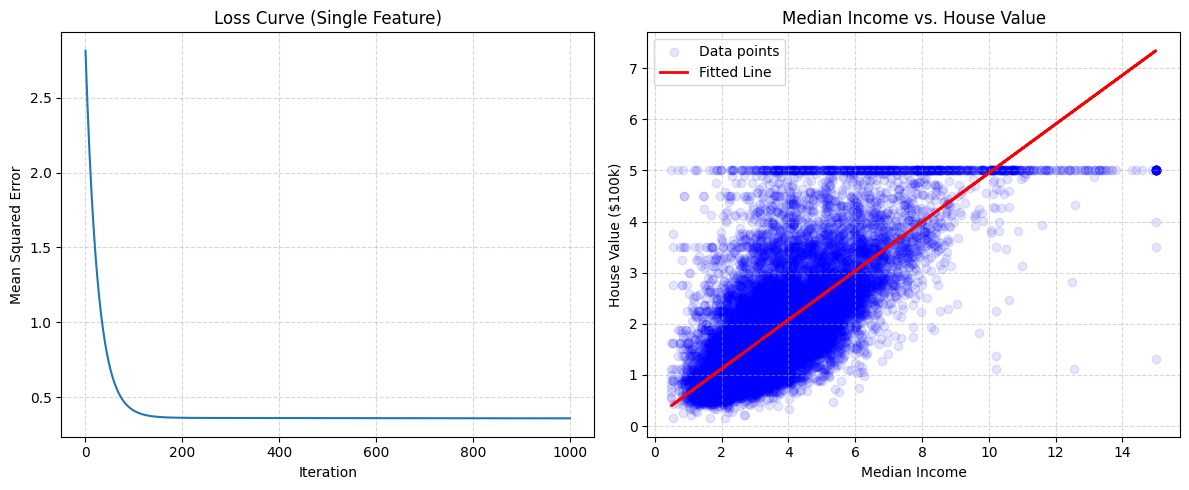

In [49]:
# Initialize and train
model_single = LinearRegressionGD(learning_rate=0.001, n_iterations=1000)
model_single.fit(X_train_single, y_train)

# --- Plotting the Loss Curve ---
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(model_single.losses)
plt.title("Loss Curve (Single Feature)")
plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.grid(True, linestyle='--', alpha=0.5)

# --- Plotting the Data and Fitted Line ---
plt.subplot(1, 2, 2)
plt.scatter(X_train_single, y_train, color='blue', alpha=0.1, label='Data points')
plt.plot(X_train_single, model_single.predict(X_train_single), color='red', linewidth=2, label='Fitted Line')
plt.title("Median Income vs. House Value")
plt.xlabel("Median Income")
plt.ylabel("House Value ($100k)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

#### 8-feature model

**A Short report of the results below**

*what changed when I went from 1 feature to all 8.*

- **Overflow:** While extending to all 8 features, I faced so many overflow errors in calculating the gradients. Then I found out, this happened due to vastly different scales of the features making the gradients grow very large leading to overflow. Re-scaling the data via z-score method seemed to fix this problem.


- **Performance Jump:** My MSE jumped from 0.7282 for single feature to 0.5562 for all 8-feature, verifying the fact that as we give more information to the model, its prediction gets better.

- **Visualization:** Since visualizing the fitted line in 8-feature version is impossible (requires 9-D graph) I used a Predicted vs. Actual plot. The more prediction values are closer to the actual ones, the more compact should the datapoints be distributed arounf $x=y$ line.


In [51]:
X_train_full, X_test_full, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale the features (Standardization: zero mean, unit variance)
# This is crucial so gradient descent converges properly on multiple features
train_mean = np.mean(X_train_full, axis=0)
train_std = np.std(X_train_full, axis=0)

X_train_scaled = (X_train_full - train_mean) / train_std
X_test_scaled = (X_test_full - train_mean) / train_std

# Train the model
model_full = LinearRegressionGD(learning_rate=0.05, n_iterations=1000)
model_full.fit(X_train_scaled, y_train)

# Evaluate on the test set
def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

# Predict and calculate MSE
y_pred_single = model_single.predict(X_test_single)
y_pred_full = model_full.predict(X_test_scaled)

mse_single = mean_squared_error(y_test, y_pred_single)
mse_full = mean_squared_error(y_test, y_pred_full)

print("Test Set Performance (MSE):")
print("-" * 30)
print(f"Single Feature (MedInc): {mse_single:.4f}")
print(f"All 8 Features:          {mse_full:.4f}")

Test Set Performance (MSE):
------------------------------
Single Feature (MedInc): 0.7282
All 8 Features:          0.5562


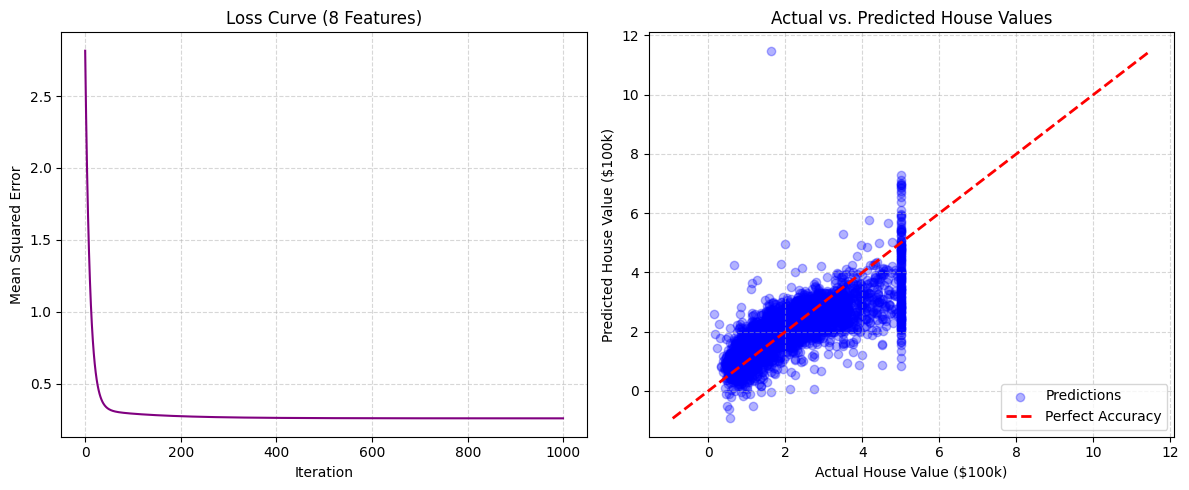

In [52]:
plt.figure(figsize=(12, 5))

# --- Subplot 1: The Loss Curve (8 Features) ---
plt.subplot(1, 2, 1)

plt.plot(model_full.losses, color='purple')
plt.title("Loss Curve (8 Features)")
plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.grid(True, linestyle='--', alpha=0.5)

# --- Subplot 2: Predicted vs. Actual Values ---
plt.subplot(1, 2, 2)

plt.scatter(y_test, y_pred_full, color='blue', alpha=0.3, label='Predictions')

# Draw the "Perfect Prediction" diagonal line
min_val = min(np.min(y_test), np.min(y_pred_full))
max_val = max(np.max(y_test), np.max(y_pred_full))
plt.plot([min_val, max_val], [min_val, max_val], color='red', 
         linewidth=2, linestyle='--', label='Perfect Accuracy')

plt.title("Actual vs. Predicted House Values")
plt.xlabel("Actual House Value ($100k)")
plt.ylabel("Predicted House Value ($100k)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Sanity Check via SKLearn

Comparing my results with scikit-learn’s `LinearRegression` outputs:

In [53]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

print("Sanity Check: Custom GD vs. scikit-learn")
print("-" * 45)

# Initialize the scikit-learn model
sklearn_model = LinearRegression()

# Fit the model (using the same scaled training data from before)
sklearn_model.fit(X_train_scaled, y_train)

# Predict on the scaled test data
y_pred_sklearn = sklearn_model.predict(X_test_scaled)

# Calculate the Mean Squared Error
mse_sklearn = mean_squared_error(y_test, y_pred_sklearn)

print(f"Custom Model (8 Features) MSE: {mse_full:.4f}")
print(f"scikit-learn Model MSE:        {mse_sklearn:.4f}")

Sanity Check: Custom GD vs. scikit-learn
---------------------------------------------
Custom Model (8 Features) MSE: 0.5562
scikit-learn Model MSE:        0.5559


### Bonus
#### MSE vs. Learning Rate Plot
Only to see how manipulating the learning rate affects the accuracy (tested for single-feature regression)

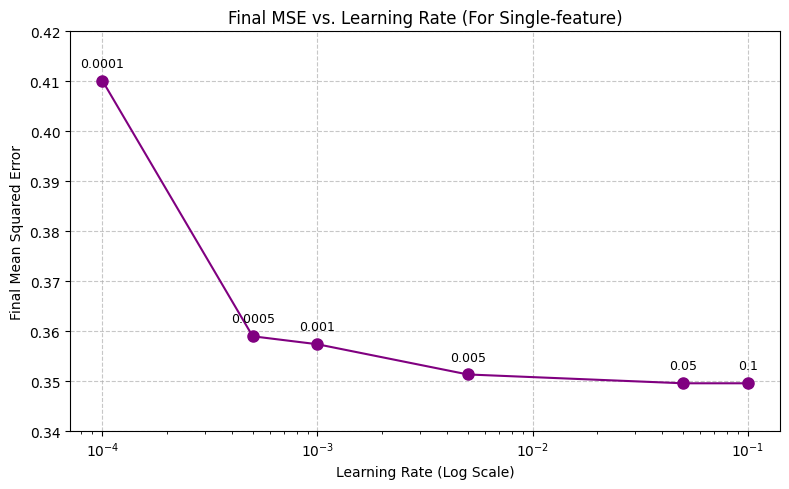

In [57]:
learning_rates = [0.1, 0.05, 0.005, 0.001, 0.0005, 0.0001]
final_mses = []

# Loop through and train a model for each learning rate
for lr in learning_rates:
    model_single = LinearRegressionGD(learning_rate=lr, n_iterations=1000)
    model_single.fit(X_train_single, y_train)
    
    # Grab the very last error value (after 1000 iterations)
    final_error = model_single.losses[-1]
    final_mses.append(final_error)


plt.figure(figsize=(8, 5))
plt.plot(learning_rates, final_mses, marker='o', linestyle='-', color='purple', markersize=8)

# --- Adding learning rate labels to each point ---
for lr, mse in zip(learning_rates, final_mses):
    # Format the label text
    label = f"{lr}"
    
    # Annotate the point
    plt.annotate(label,                      # The text to display
                 (lr, mse),                  # The exact (x, y) coordinates of the point [cite: 63]
                 textcoords="offset points", # Tell matplotlib to use an offset [cite: 63]
                 xytext=(0, 10),             # Shift the text 10 points UP (so it doesn't cover the dot) [cite: 63]
                 ha='center',                # Center the text horizontally over the dot [cite: 64]
                 fontsize=9)                 # Make the font a bit smaller [cite: 64]
# ---------------------------------------------------

# Formatting the plot
plt.title("Final MSE vs. Learning Rate (For Single-feature)")
plt.xlabel("Learning Rate (Log Scale)")
plt.ylabel("Final Mean Squared Error")

plt.xscale('log')
plt.ylim(0.34, 0.42)

plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()